# Employee Attrition Prediction Using Machine Learning

## 1. Project Overview

This project investigates employee attrition prediction using machine learning and the IBM HR Analytics Employee Attrition & Performance dataset, which contains **1,470 employee records**. Four supervised learning algorithms—**Logistic Regression, Decision Tree, Random Forest, and XGBoost**—are evaluated to identify patterns associated with employee departures.

The analysis compares approaches to handling class imbalance, including **class weighting and SMOTE**, alongside hyperparameter tuning and cross-validation. Performance is assessed using precision, recall, F1-score, ROC-AUC, and average precision.


## 2. Business Problem

Employee attrition can create recruitment costs, operational disruptions, and losses of organizational knowledge. Understanding factors associated with employee departures can help organizations investigate retention challenges and develop better workforce planning strategies.

Predicting attrition is challenging because employees who leave represent a smaller proportion of the dataset. A model may achieve high accuracy by predicting that most employees will stay while failing to identify employees who leave. Therefore, this project emphasizes **minority-class detection** and evaluates the trade-offs between identifying potential departures and incorrectly flagging employees who remain.

## 3. Research Questions

1. Which employee characteristics are most influential in predicting attrition, particularly overtime, job satisfaction, and work environment satisfaction?
2. How effectively can machine learning predict employee attrition, and which model provides the strongest cross-validated performance?
3. How do class imbalance strategies and hyperparameter tuning affect attrition prediction performance and incorrect prediction rates?
4. How do classification thresholds, prediction errors, and subgroup performance differences affect the reliability of employee attrition predictions?
5. Based on influential predictors, prediction errors, and subgroup differences, which workforce conditions should retention teams investigate, and what safeguards should they consider?

## 4. Dataset Description and Provenance

**Source:** IBM HR Analytics Employee Attrition & Performance dataset, distributed on Kaggle: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset. The supplied file has **1,470 rows and 35 columns**, including the `Attrition` target. The data are synthetic; the generation process and applicability to real workplaces are not independently established here. The project reports associations and predictive performance within this dataset only.

## 5. Methods and Evaluation Plan

The study uses stratified **60% training / 20% validation / 20% testing** partitions. Preprocessing, resampling, and hyperparameter search occur within five-fold training cross-validation. Four algorithms × three imbalance strategies × baseline/tuned versions produce **24 configurations**.

The **predefined model-selection rule** ranks configurations by mean training cross-validation average precision (AP), using validation AP only to break exact ties. Validation AP and ROC-AUC are reported as development-set comparisons, while the **classification threshold** is selected using validation predictions. Because the threshold is optimized on this same validation partition, its threshold-dependent validation metrics are not an independent estimate of final performance. The held-out test is evaluated after the model and threshold have been fixed.

In [1]:
import os

# Limit loky worker detection on Windows before ML imports.
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
    precision_score, recall_score, f1_score, balanced_accuracy_score, accuracy_score)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from joblib import dump
SEED = 42
sns.set_theme(style='whitegrid')
ROOT = Path.cwd()
if ROOT.name.lower() == 'notebooks': ROOT = ROOT.parent
DATA = ROOT / 'data' / 'WA_Fn-UseC_-HR-Employee-Attrition.csv'
FIG = ROOT / 'figures'; RESULTS = ROOT / 'results'
FIG.mkdir(parents=True, exist_ok=True); RESULTS.mkdir(parents=True, exist_ok=True)
def save_plot(filename):
    plt.savefig(FIG / filename, dpi=180, bbox_inches='tight')
    print(f'Saved figure: {filename}')
print('Project setup ready.')

Project setup ready.


## 6. Data Dictionary and Variable Roles

**Outcome:** `Attrition` (`Yes` = 1, `No` = 0). **Illustrative numeric predictors:** `Age`, `MonthlyIncome`, `YearsAtCompany`, `JobSatisfaction`, `TotalWorkingYears`, and `DistanceFromHome`. **Illustrative categorical predictors:** `OverTime`, `BusinessTravel`, `JobRole`, `Gender`, and `MaritalStatus`. The full column-level inventory, types, missing counts, and cardinalities are displayed in the following audit output. `EmployeeNumber` is an identifier; constant columns (`EmployeeCount`, `Over18`, `StandardHours`) are removed before modeling. These fields are not evidence of causal relationships.

### Predictor inventory and consistency check

The executed data audit contains **35 original columns**: **one target (`Attrition`)**, **one record identifier (`EmployeeNumber`)**, **three constant fields (`EmployeeCount`, `Over18`, `StandardHours`)**, and **30 retained predictors**. The split code explicitly drops the target and the four excluded fields before fitting. The retained predictors comprise **23 numeric and 7 categorical fields**; the lists below match the input schema and the feature-selection logic in the executed notebook.

| Role | Fields | Treatment |
|---|---|---|
| Target | `Attrition` | Encoded `No = 0`, `Yes = 1`; never included among predictors |
| Identifier | `EmployeeNumber` | Excluded to avoid learning from record IDs |
| Constant fields | `EmployeeCount`, `Over18`, `StandardHours` | Excluded because they have no variation |
| Numeric predictors (23) | `Age`, `DailyRate`, `DistanceFromHome`, `Education`, `EnvironmentSatisfaction`, `HourlyRate`, `JobInvolvement`, `JobLevel`, `JobSatisfaction`, `MonthlyIncome`, `MonthlyRate`, `NumCompaniesWorked`, `PercentSalaryHike`, `PerformanceRating`, `RelationshipSatisfaction`, `StockOptionLevel`, `TotalWorkingYears`, `TrainingTimesLastYear`, `WorkLifeBalance`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager` | Median imputation and standardization inside each fold |
| Categorical predictors (7) | `BusinessTravel`, `Department`, `EducationField`, `Gender`, `JobRole`, `MaritalStatus`, `OverTime` | Most-frequent imputation and one-hot encoding inside each fold |

**Data completeness:** The executed audit reports **zero missing values in all 35 columns** and **zero exact duplicate records**. Therefore, imputation is a protective pipeline component for potential future missingness, **not an operation that changes values in this executed dataset**. A missing-data sensitivity test was not performed because the supplied dataset contains no missing values. The dataset cannot establish how the pipeline would perform with real-world missingness. If later data include substantial missingness, missingness mechanisms and alternative handling should be evaluated before use.


## 7. Data Loading, Provenance, and Initial Audit

**Dataset:** This project uses the IBM HR Analytics Employee Attrition & Performance dataset, stored in the `data/` directory as `WA_Fn-UseC_-HR-Employee-Attrition.csv`.

In [2]:
if not DATA.exists():
    raise FileNotFoundError(f'Expected CSV: data/{DATA.name}. Put it in the project data folder.')
df = pd.read_csv(DATA)
assert 'Attrition' in df.columns, 'The dataset must contain Attrition.'
print('Shape:', df.shape)
display(df.head())
display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(), 'unique':df.nunique(dropna=False)}))
print('Exact duplicates:', df.duplicated().sum())
print('Target distribution:'); display(df['Attrition'].value_counts(dropna=False).to_frame('count'))
assert set(df['Attrition'].dropna().unique()) == {'Yes','No'}, 'Unexpected target values; inspect dataset.'
assert df['Attrition'].notna().all(), 'Target has missing values.' 

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


,dtype,missing,unique
Age,int64,0,43
Attrition,object,0,2
BusinessTravel,object,0,3
DailyRate,int64,0,886
Department,object,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,object,0,6
EmployeeCount,int64,0,1
EmployeeNumber,int64,0,1470


Exact duplicates: 0
Target distribution:


,count
Attrition,
No,1233
Yes,237


### Data Quality and Class Distribution — Interpretation

The executed audit reports **1,470 rows × 35 columns**, **zero exact duplicate rows**, and **237 `Yes` versus 1,233 `No`** outcomes (approximately **16.1% attrition**). The displayed missing-value audit reports no missing entries. Median and most-frequent imputation are retained within training-fold pipelines as a reproducible safeguard, not because missingness was observed in this file. Verify types and unexpected values if the dataset is replaced.

A trivial classifier predicting `No` for every employee would achieve **1,233 / 1,470 ≈ 83.9% accuracy** on the complete dataset while identifying **zero departures**. Therefore, accuracy alone is not an adequate selection criterion. The analysis prioritizes **average precision (AP / PR-AUC)** for ranking and reports recall, precision, specificity, ROC-AUC, and balanced accuracy for thresholded decisions.

## 8. Exploratory Data Analysis

Saved figure: attrition_distribution.png


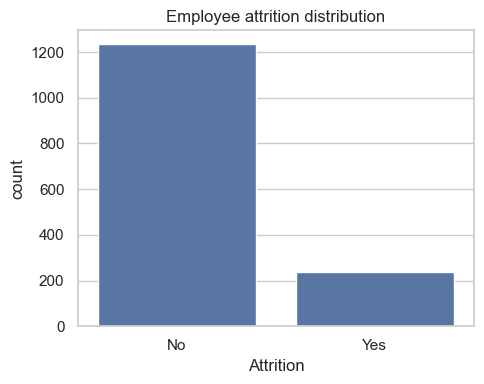

Saved figure: eda_age.png


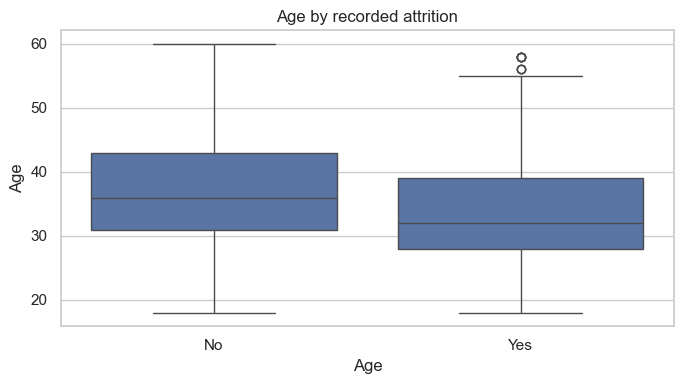

Saved figure: eda_monthlyincome.png


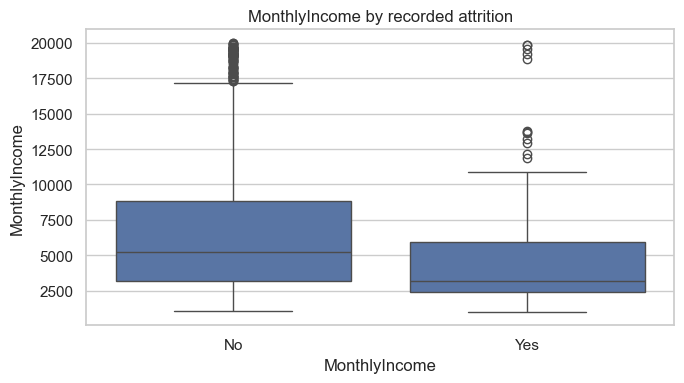

Saved figure: eda_yearsatcompany.png


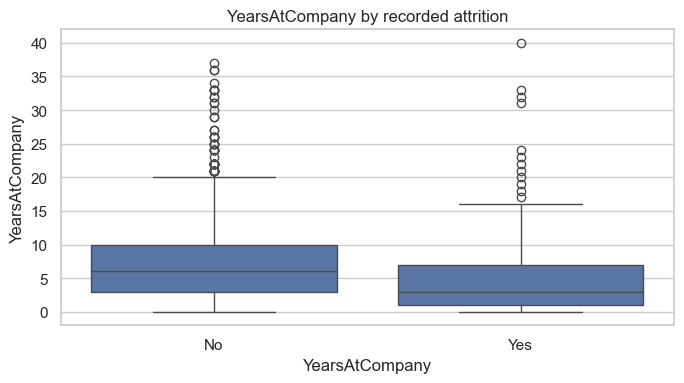

Saved figure: eda_jobsatisfaction.png


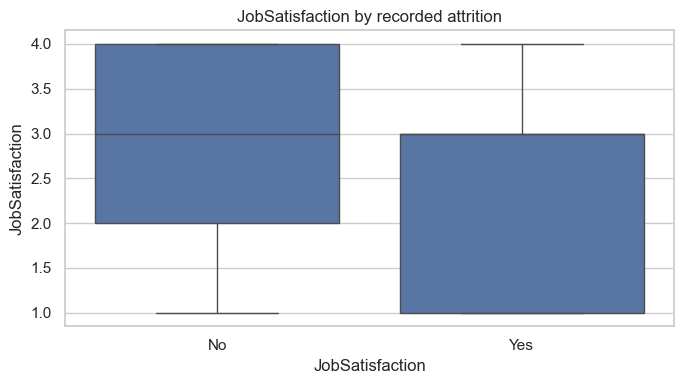

Saved figure: eda_overtime.png


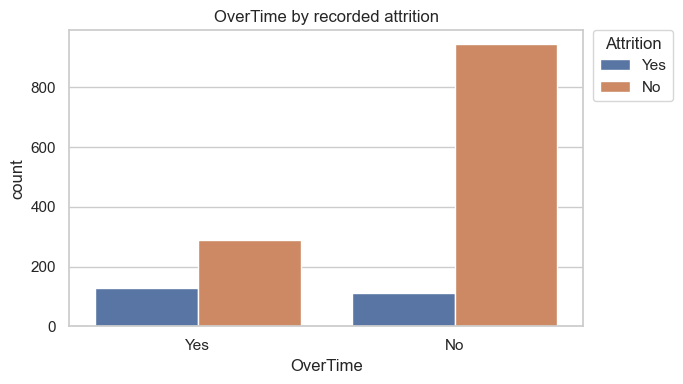

In [3]:
# Employee attrition distribution
fig, ax = plt.subplots(figsize=(5, 4))

sns.countplot(
    data=df,
    x='Attrition',
    order=['No', 'Yes'],
    ax=ax
)

ax.set_title('Employee attrition distribution')

plt.tight_layout()
save_plot('attrition_distribution.png')
plt.show()


# Individual feature distributions by recorded attrition
eda_columns = [
    'Age',
    'MonthlyIncome',
    'YearsAtCompany',
    'JobSatisfaction',
    'OverTime'
]

for col in eda_columns:

    if col not in df.columns:
        continue

    fig, ax = plt.subplots(figsize=(7, 4))

    # Numerical features: boxplots
    if pd.api.types.is_numeric_dtype(df[col]):

        sns.boxplot(
            data=df,
            x='Attrition',
            y=col,
            order=['No', 'Yes'],
            ax=ax
        )

    # Categorical features: countplots
    else:

        sns.countplot(
            data=df,
            x=col,
            hue='Attrition',
            hue_order=['Yes', 'No'],
            ax=ax
        )

        # Place the legend outside the plotting area
        ax.legend(
            title='Attrition',
            loc='upper left',
            bbox_to_anchor=(1.02, 1),
            borderaxespad=0,
            frameon=True
        )

    # Chart formatting
    ax.set_title(f'{col} by recorded attrition')
    ax.set_xlabel(col)

    # Adjust spacing for labels and outside legend
    fig.tight_layout()

    # Save figure
    save_plot(f'eda_{col.lower()}.png')

    # Display figure
    plt.show()

### Exploratory Data Analysis — Interpretation

The six EDA figures describe the **full synthetic dataset**; they are exploratory, not evidence of causation or out-of-sample accuracy.

**Attrition distribution.** Of 1,470 records, **1,233 (83.9%)** are labeled `No` and **237 (16.1%)** `Yes`. Always predicting `No` would achieve 83.9% accuracy but **zero attrition recall**, motivating class-sensitive metrics.

**Age.** The `Yes` group has a **lower median age**, but the distributions overlap substantially; age alone cannot reliably separate the classes.

**Monthly income.** The `Yes` group has a **lower median and generally lower interquartile range**, with overlapping distributions and high-income outliers. The plot does not isolate an independent income effect.

**Years at company.** Records labeled `Yes` generally show **shorter tenure and a lower median**, although longer-tenured employees appear in both groups.

**Job satisfaction.** Median satisfaction is approximately **2** for `Yes` and **3** for `No`. This is an ordinal **1–4 scale**, not a continuous causal measure.

**Overtime.** The `OverTime = Yes` group shows relatively more departures compared with employees staying; `OverTime = No` is dominated by employees staying. **Counts are not within-group attrition rates** unless divided by group totals.

**Overall.** These associations suggest useful predictors but cannot establish causes or justify retention interventions. The later validation importance analysis measures model reliance; held-out testing evaluates predictive performance.

## 9. Leakage review and stratified holdouts
Remove identifiers and constant fields. Never use an employee identifier as a predictor. A 60/20/20 split is created before fitting preprocessing or tuning.

In [4]:
drop_cols = [x for x in ['EmployeeNumber','EmployeeCount','Over18','StandardHours'] if x in df]
X = df.drop(columns=['Attrition']+drop_cols)
y = df['Attrition'].map({'No':0,'Yes':1}).astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=.40,stratify=y,random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=.50,stratify=y_temp,random_state=SEED)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()
print('Train / validation / test:', len(X_train),len(X_val),len(X_test))
print('Train prevalence:',round(y_train.mean(),4),'Validation prevalence:',round(y_val.mean(),4))
print('Numeric:',len(num_cols),'Categorical:',len(cat_cols))
assert not set(X_train.index)&set(X_val.index)
assert not set(X_train.index)&set(X_test.index)

Train / validation / test: 882 294 294
Train prevalence: 0.161 Validation prevalence: 0.1633
Numeric: 23 Categorical: 7


## 10. Predictor Availability and Leakage Check

`EmployeeNumber` is excluded because it identifies records rather than representing a deployable predictor. The three constant fields add no predictive variation. The remaining columns should be checked against the intended real-world prediction moment: some HR variables might be measured or updated after an employee has already decided to leave. Their timing cannot be verified from this synthetic snapshot, so operational leakage risk remains a limitation.

### Temporal availability audit

| Predictor group | Availability concern | Research treatment |
|---|---|---|
| Employee identifiers and constants | Record IDs can encode arbitrary ordering; constants cannot generalize | Explicitly excluded in code |
| Employment history (`YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager`) | Could be valid if recorded **before** the prediction date, but a snapshot does not prove that timing | Retained for the synthetic benchmark; timing unverified |
| HR assessments (`JobSatisfaction`, `EnvironmentSatisfaction`, `JobInvolvement`, `PerformanceRating`, `WorkLifeBalance`) | Surveys or ratings collected after a resignation decision could leak information | Retained for research; require timestamp and collection-process audit in any real setting |
| Work arrangements and compensation (`OverTime`, `BusinessTravel`, `MonthlyIncome`, `StockOptionLevel`, etc.) | May change shortly before exit and may reflect HR interventions or an already-known departure | Retained for research; prospective availability cannot be established |
| Demographic characteristics (`Gender`, `MaritalStatus`, `Age`) | May serve as protected attributes or proxies and raise fairness concerns | Included in this benchmark; real use would require a separate necessity, legal, and fairness review |

**Leakage Assessment:** Identifier and constant columns were excluded, and preprocessing was performed within cross-validation pipelines to reduce data leakage. However, because the synthetic dataset lacks feature observation dates and attrition-event timestamps, potential temporal leakage cannot be fully ruled out.

### Train, Validation, and Test Split — Interpretation

The executed split contains **882 training**, **294 validation**, and **294 testing** observations. Stratification keeps attrition prevalence similar across partitions. Model search and cross-validation use training only; threshold analysis and permutation importance use validation. Test results are reserved for final descriptive assessment.

## 11. Fold-safe preprocessing and 24 configurations
SMOTE is a synthetic minority oversampling technique (Chawla et al., 2002). Each algorithm is evaluated with original class distribution, class weights, and SMOTE. Each strategy has a baseline and tuned version. `RandomizedSearchCV` uses **10 candidates** and **5 stratified folds**. SMOTE occurs inside the training fold only. XGBoost receives binary-encoded targets.

In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', SKPipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
        ('cat', SKPipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                            ('onehot',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),cat_cols)
    ], sparse_threshold=0)

def make_model(algorithm, strategy):
    weighted = strategy == 'Class weights'
    if algorithm == 'Logistic Regression':
        return LogisticRegression(max_iter=2000, class_weight='balanced' if weighted else None,random_state=SEED)
    if algorithm == 'Decision Tree':
        return DecisionTreeClassifier(class_weight='balanced' if weighted else None,random_state=SEED)
    if algorithm == 'Random Forest':
        return RandomForestClassifier(n_estimators=200,n_jobs=-1,class_weight='balanced' if weighted else None,random_state=SEED)
    ratio = float((y_train==0).sum()/(y_train==1).sum())
    return XGBClassifier(n_estimators=200,eval_metric='logloss',tree_method='hist',
                         scale_pos_weight=ratio if weighted else 1.0,
                         random_state=SEED,n_jobs=1)

spaces = {
    'Logistic Regression':{'model__C':np.logspace(-2,2,30)},
    'Decision Tree':{'model__max_depth':[2,3,4,5,7,10,None],
                     'model__min_samples_leaf':[1,2,5,10,20]},
    'Random Forest':{'model__n_estimators':[100,200,300],
                     'model__max_depth':[3,5,8,None],
                     'model__min_samples_leaf':[1,2,5,10]},
    'XGBoost':{'model__n_estimators':[100,200,300],
               'model__max_depth':[2,3,4,5],
               'model__learning_rate':[.01,.03,.05,.1],
               'model__subsample':[.7,.85,1.0]}
}
def make_pipe(algorithm,strategy):
    steps=[('prep',make_preprocessor())]
    if strategy=='SMOTE':steps.append(('smote',SMOTE(random_state=SEED)))
    steps.append(('model',make_model(algorithm,strategy)))
    return Pipeline(steps)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
algorithms=['Logistic Regression','Decision Tree','Random Forest','XGBoost']
strategies=['Original (imbalanced)','Class weights','SMOTE']
print('Prepared',len(algorithms)*len(strategies)*2,'configurations.')

Prepared 24 configurations.


## 12. Preprocessing, Model Selection, and Experimental Design

### Preprocessing and justification
Numeric predictors are processed with median imputation and standard scaling, while categorical predictors use most-frequent imputation and one-hot encoding with unknown-category handling. These transformations are fitted within each training fold, not on validation or test records. The executed data audit found no missing values, so imputation is a defensive pipeline design rather than a remedy for observed missingness; no evidence here establishes that median or mode imputation is optimal for future incomplete data. When SMOTE is applied, synthetic minority samples are generated **inside each training fold after preprocessing**, preventing validation-fold information from entering the resampling process. **Important SMOTE limitation:** Because categorical variables are one-hot encoded *before* ordinary SMOTE, interpolation can create fractional values in encoded category columns that do not represent actual categories. This is a methodological limitation of the SMOTE configurations; a future comparison should use a categorical-aware approach (for example, SMOTENC before one-hot encoding) and rerun the affected experiments. It does not alter the selected class-weighted Logistic Regression model, which does not use SMOTE.

### Why these four algorithms?
**Logistic Regression** provides a regularized, interpretable linear benchmark. **Decision Tree** tests whether a single set of nonlinear decision rules is sufficient. **Random Forest** averages many trees to reduce sensitivity to individual splits. **XGBoost** uses sequentially boosted trees to capture more complex patterns. Evaluating all four on the same partitions and scoring protocol helps determine whether increased complexity produces a meaningful improvement over the simpler benchmark.

### Experimental design and comparability
Each algorithm is evaluated under three imbalance strategies: **original class distribution**, **class weighting**, and **SMOTE**. Each strategy has a baseline and a tuned variant, producing **4 algorithms × 3 strategies × 2 variants = 24 configurations**. All use the same five-fold stratified training cross-validation and average precision (AP) as the primary ranking metric. Class weighting is implemented using each algorithm's supported mechanism; weighting and SMOTE are evaluated as alternatives rather than combined. Tuned candidates are searched using `RandomizedSearchCV` with ten sampled hyperparameter settings per configuration. The separate validation set supports model and threshold assessment, while the held-out test set is reserved for the final frozen evaluation. A uniform evaluation protocol improves fairness of comparison, although search spaces and model-specific weighting implementations are not identical.

## 13. Cross-Validation, Tuning, and Validation Comparison

Each configuration is evaluated with five-fold stratified training cross-validation; tuned variants use ten sampled hyperparameter settings. The predefined selection rule prioritizes **mean training CV AP** and uses **validation AP only as an exact-tie breaker**. Validation AP and ROC-AUC are also displayed for transparent comparison, but they do not override a non-tied CV ranking.

Training CV scores are useful for relative comparison, but the highest scores may be optimistic because tuning and subsequent ranking reuse training-fold information. Validation provides an additional development check, not an independent test of the validation-selected classification threshold. The final test partition is reserved for the frozen evaluation.

In [6]:
rows=[]; fitted={}; completion_rows=[]
for algorithm in algorithms:
    for strategy in strategies:
        base=make_pipe(algorithm,strategy)
        scores=cross_validate(base,X_train,y_train,cv=cv,scoring='average_precision',n_jobs=1)
        base.fit(X_train,y_train)
        p=base.predict_proba(X_val)[:,1]
        key=(algorithm,strategy,'Baseline')
        fitted[key]=base
        rows.append({'Algorithm':algorithm,'Strategy':strategy,'Version':'Baseline',
                     'CV AP':scores['test_score'].mean(),'CV SD':scores['test_score'].std(),
                     'Validation AP':average_precision_score(y_val,p),
                     'Validation ROC-AUC':roc_auc_score(y_val,p)})
        search = RandomizedSearchCV(make_pipe(algorithm, strategy),
                    spaces[algorithm],n_iter=10,scoring='average_precision',
                    cv=cv,random_state=SEED,n_jobs=1,refit=True,
                    error_score='raise',verbose=0)
        search.fit(X_train,y_train)
        p=search.best_estimator_.predict_proba(X_val)[:,1]
        key=(algorithm,strategy,'Tuned')
        fitted[key]=search.best_estimator_
        rows.append({'Algorithm':algorithm,'Strategy':strategy,'Version':'Tuned',
                     'CV AP':search.best_score_,'CV SD':search.cv_results_['std_test_score'][search.best_index_],
                     'Validation AP':average_precision_score(y_val,p),
                     'Validation ROC-AUC':roc_auc_score(y_val,p)})
        completion_rows.append({'Algorithm':algorithm,'Imbalance Strategy':strategy,'Baseline':'Completed','Tuned':'Completed'})
print('Model training completion summary:')
display(pd.DataFrame(completion_rows).style.hide(axis='index'))
comparison=pd.DataFrame(rows).sort_values(['CV AP','Validation AP'],ascending=False).reset_index(drop=True)
display(comparison.style.format({'CV AP':'{:.4f}','CV SD':'{:.4f}','Validation AP':'{:.4f}','Validation ROC-AUC':'{:.4f}'}).background_gradient(subset=['CV AP','Validation AP'],cmap='Blues'))
comparison.to_csv(RESULTS/'model_comparison.csv',index=False)
print('Training prevalence baseline AP:',round(y_train.mean(),4))
print('Validation prevalence baseline AP:',round(y_val.mean(),4))

Model training completion summary:


Algorithm,Imbalance Strategy,Baseline,Tuned
Logistic Regression,Original (imbalanced),Completed,Completed
Logistic Regression,Class weights,Completed,Completed
Logistic Regression,SMOTE,Completed,Completed
Decision Tree,Original (imbalanced),Completed,Completed
Decision Tree,Class weights,Completed,Completed
Decision Tree,SMOTE,Completed,Completed
Random Forest,Original (imbalanced),Completed,Completed
Random Forest,Class weights,Completed,Completed
Random Forest,SMOTE,Completed,Completed
XGBoost,Original (imbalanced),Completed,Completed


,Algorithm,Strategy,Version,CV AP,CV SD,Validation AP,Validation ROC-AUC
0,Logistic Regression,Class weights,Tuned,0.6503,0.0635,0.6202,0.8457
1,Logistic Regression,Original (imbalanced),Tuned,0.6498,0.0701,0.6583,0.8531
2,Logistic Regression,Original (imbalanced),Baseline,0.6443,0.0714,0.6263,0.8472
3,Logistic Regression,Class weights,Baseline,0.6407,0.0656,0.5731,0.8320
4,XGBoost,Original (imbalanced),Tuned,0.6402,0.0579,0.5489,0.8034
5,Logistic Regression,SMOTE,Tuned,0.6366,0.0580,0.6110,0.8426
6,XGBoost,SMOTE,Tuned,0.6365,0.0899,0.5648,0.8191
7,Logistic Regression,SMOTE,Baseline,0.6263,0.0622,0.5810,0.8339
8,XGBoost,Class weights,Tuned,0.6226,0.0778,0.5636,0.8259
9,XGBoost,SMOTE,Baseline,0.6035,0.0535,0.5256,0.8028


Training prevalence baseline AP: 0.161
Validation prevalence baseline AP: 0.1633


### Cross-Validation and Hyperparameter Tuning Results — Interpretation

The comparison covers **24 configurations**, reporting mean five-fold training average precision (AP), fold SD, validation AP, and validation ROC-AUC. Each tuned configuration searches **10 hyperparameter candidates**. Selection ranks **training CV AP first**, with validation AP only breaking ties; tuning on the same CV folds may make leading CV estimates optimistic.

**Selected configuration.** **Logistic Regression — Class weights — Tuned** achieved **CV AP 0.6503 (SD 0.0635)**, **validation AP 0.6202** (gap **0.0301**), and **validation ROC-AUC 0.8457**. **Logistic Regression — Original — Tuned** achieved **CV AP 0.6498**, **validation AP 0.6583**, and **validation ROC-AUC 0.8531**. The weighted model won under the predefined **CV-first rule**, **not** because it had the best validation metrics. Its CV AP lead was only **0.0005**; this descriptive difference is **not evidence of statistically significant superiority**. Fold SD is not a confidence interval, and repeated or nested resampling would better assess ranking stability.

**Other CV–validation gaps.** **XGBoost — Original — Tuned** fell from **0.6402 to 0.5489 AP** (gap **0.0913**), and **Random Forest — Original — Tuned** from **0.5952 to 0.4809** (gap **0.1143**). Sampling variation, relatively few departures, and selection on CV folds may contribute; these gaps alone do not prove overfitting.

**Tuning was not uniformly beneficial.** For original Logistic Regression, tuning raised **CV AP 0.6443 → 0.6498** and **validation AP 0.6263 → 0.6583**. For weighted Logistic Regression, the changes were **0.6407 → 0.6503** and **0.5731 → 0.6202**, respectively. These are matched descriptive comparisons, not a universal tuning benefit.

## 14. Model Comparison and Imbalance Strategy Discussion

The model comparison evaluates original training, class weighting, and SMOTE within each algorithm. Performance varies across configurations, and no single imbalance strategy consistently provides the strongest validation results. Class weighting changes how model errors are penalized, whereas SMOTE generates additional minority-class training examples. These approaches should therefore be assessed through cross-validation and independent evaluation rather than assumed to improve performance.


## 15. Why Average Precision Matters

Training attrition prevalence is **0.1610** and validation prevalence is **0.1633**, establishing the approximate random-ranking AP baselines. Precision–recall evaluation is especially relevant for imbalanced classification (Saito & Rehmsmeier, 2015). AP summarizes the precision–recall trade-off across thresholds. ROC-AUC measures ranking across false-positive rates. Neither alone specifies the operational costs of false positives and false negatives.

## 16. Model selection and validation threshold analysis
Select the best training-CV configuration. Compare thresholds on validation only. The threshold rule maximizes validation F1 among thresholds with **recall ≥ 0.50**, when available; otherwise it maximizes validation F1 without that constraint and explicitly reports the fallback. This is a research choice, not a clinical or HR operating policy.

Selected: ('Logistic Regression', 'Class weights', 'Tuned') Validation threshold: 0.6


,Threshold,Precision,Recall,Specificity,F1,Balanced accuracy,Positive prediction rate
0,0.050,0.1790,0.9583,0.1423,0.3016,0.5503,0.8741
1,0.075,0.1893,0.9583,0.1992,0.3162,0.5788,0.8265
2,0.100,0.2063,0.9583,0.2805,0.3395,0.6194,0.7585
3,0.125,0.2190,0.9583,0.3333,0.3566,0.6458,0.7143
4,0.150,0.2266,0.9583,0.3618,0.3665,0.6601,0.6905
5,0.175,0.2396,0.9583,0.4065,0.3833,0.6824,0.6531
6,0.200,0.2473,0.9583,0.4309,0.3932,0.6946,0.6327
7,0.225,0.2614,0.9583,0.4715,0.4107,0.7149,0.5986
8,0.250,0.2711,0.9375,0.5081,0.4206,0.7228,0.5646
9,0.275,0.2933,0.9167,0.5691,0.4444,0.7429,0.5102


Saved figure: threshold_tradeoffs.png


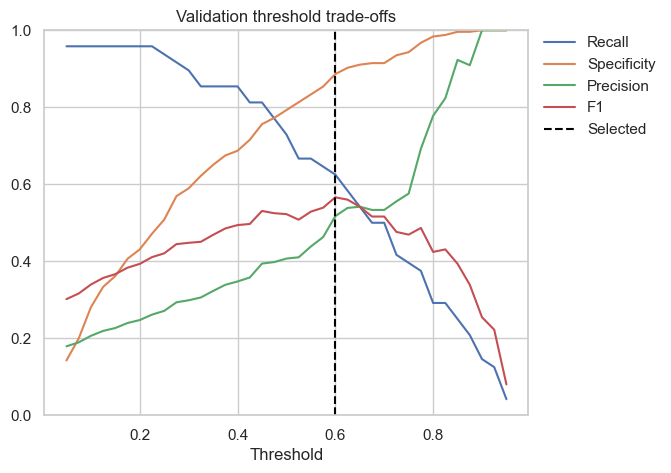

In [7]:
winner=comparison.iloc[0]
winning_key=(winner['Algorithm'],winner['Strategy'],winner['Version'])
selected=fitted[winning_key]
p_val=selected.predict_proba(X_val)[:,1]
thresholds=np.round(np.arange(.05,.951,.025),3)
threshold_rows=[]
for t in thresholds:
    yp=(p_val>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_val,yp,labels=[0,1]).ravel()
    threshold_rows.append({'Threshold':t,'Precision':precision_score(y_val,yp,zero_division=0),
                           'Recall':recall_score(y_val,yp,zero_division=0),
                           'Specificity':tn/(tn+fp) if tn+fp else np.nan,
                           'F1':f1_score(y_val,yp,zero_division=0),
                           'Balanced accuracy':balanced_accuracy_score(y_val,yp),
                           'Positive prediction rate':yp.mean()})
threshold_df=pd.DataFrame(threshold_rows)
eligible=threshold_df[threshold_df['Recall']>=.50]
if eligible.empty:
    print('WARNING: No threshold achieves validation recall >= 0.50; using highest validation F1.')
    eligible=threshold_df
chosen=eligible.sort_values(['F1','Balanced accuracy'],ascending=False).iloc[0]
chosen_threshold=float(chosen['Threshold'])
print('Selected:',winning_key,'Validation threshold:',chosen_threshold)
display(threshold_df.round(4))
threshold_df.to_csv(RESULTS/'validation_threshold_tradeoffs.csv',index=False)
ax=threshold_df.plot(x='Threshold',y=['Recall','Specificity','Precision','F1'],figsize=(8,5))
ax.axvline(chosen_threshold,color='black',ls='--',label='Selected')
ax.set_ylim(0,1); ax.set_title('Validation threshold trade-offs')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
fig = ax.get_figure()
fig.subplots_adjust(right=0.73)
save_plot('threshold_tradeoffs.png'); plt.show()
if winner['Validation AP'] <= y_val.mean():
    print('WARNING: Selected model validation AP does not exceed the prevalence baseline.')

### Selected Model and Threshold Results — Interpretation

The executed notebook selected **Logistic Regression — Class weights — Tuned** based on its comparison rule. The validation-selected threshold is **0.60**. The threshold search maximizes validation F1 among candidates with at least **50% validation recall**; this is a stated analytic preference, not a clinically or operationally validated policy. The threshold graph illustrates how recall, specificity, precision, and F1 change as the decision threshold moves.

**Selection-rule qualification:** Logistic Regression with class weighting and tuning was selected under the notebook's **predefined CV-first ranking rule**, not because it dominated every evaluation metric. Its mean training CV AP was **0.6503**, only **0.0005** above tuned Logistic Regression on the original class distribution (**0.6498**). The unweighted tuned alternative performed better on validation AP (**0.6583** versus **0.6202**) and validation ROC-AUC (**0.8531** versus **0.8457**). This very small CV advantage does not establish that class weighting is meaningfully superior. The final test set was not used to choose between these configurations; the result should be described as the **selected model under the stated procedure**, rather than a universally best algorithm.

## 17. Classification Error Trade-offs

A lower threshold generally flags more employees and may improve recall while increasing false positives. A higher threshold may improve precision or specificity while missing more departures. Because the output concerns synthetic employees, the threshold is useful for demonstrating trade-offs, not for recommending action against specific individuals.

## 18. Validation curves and feature importance
Permutation importance is computed on **validation data**, not the test set. It measures predictive dependence, not causality.

Saved figure: validation_pr_curve.png


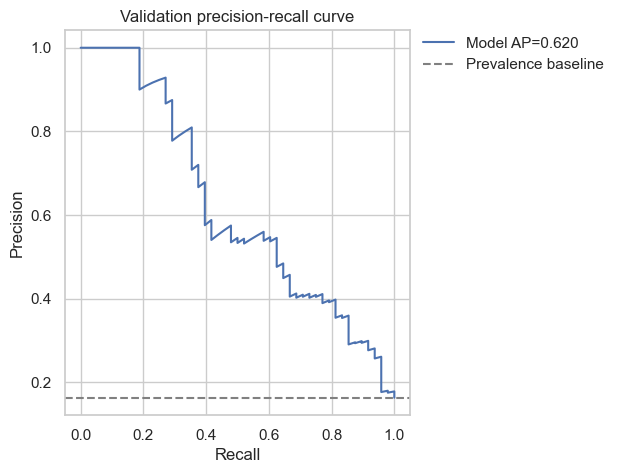

Saved figure: validation_roc_curve.png


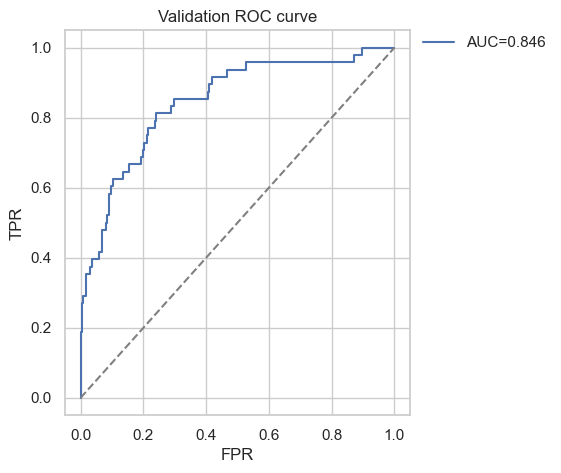

,Feature,AP importance,SD
18,OverTime,0.2461,0.0177
13,JobSatisfaction,0.0666,0.0131
7,EnvironmentSatisfaction,0.0561,0.0141
23,TotalWorkingYears,0.0531,0.0178
10,JobInvolvement,0.0427,0.0088
15,MonthlyIncome,0.0395,0.0100
27,YearsInCurrentRole,0.0367,0.0128
29,YearsWithCurrManager,0.0347,0.0126
4,DistanceFromHome,0.0340,0.0220
1,BusinessTravel,0.0337,0.0106


Saved figure: feature_importance.png


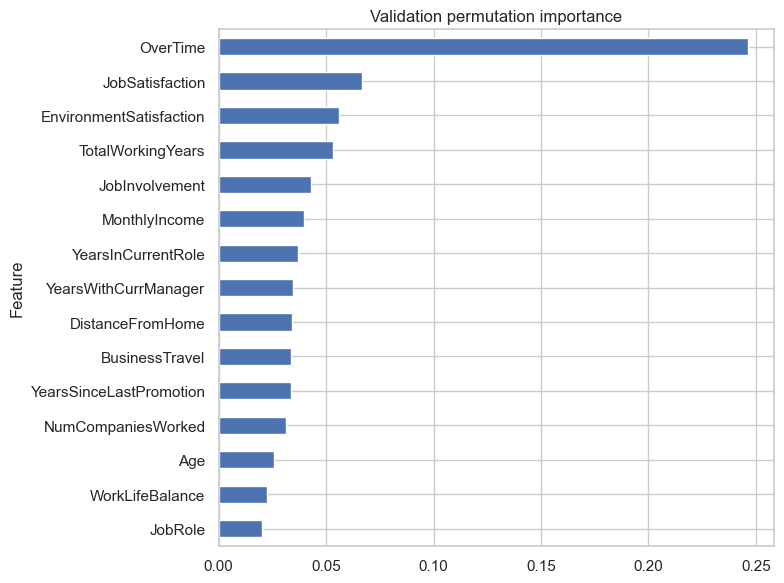

In [8]:
precision,recall,_=precision_recall_curve(y_val,p_val)
fpr,tpr,_=roc_curve(y_val,p_val)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(recall,precision,label=f'Model AP={average_precision_score(y_val,p_val):.3f}')
ax.axhline(y_val.mean(),ls='--',color='gray',label='Prevalence baseline')
ax.set(xlabel='Recall',ylabel='Precision',title='Validation precision-recall curve')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
fig.subplots_adjust(right=0.70)
save_plot('validation_pr_curve.png');plt.show()
fig,ax=plt.subplots(figsize=(6,5));ax.plot(fpr,tpr,label=f'AUC={roc_auc_score(y_val,p_val):.3f}')
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='FPR',ylabel='TPR',title='Validation ROC curve')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
fig.subplots_adjust(right=0.70)
save_plot('validation_roc_curve.png');plt.show()
imp=permutation_importance(selected,X_val,y_val,scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'Feature':X_val.columns,'AP importance':imp.importances_mean,'SD':imp.importances_std}).sort_values('AP importance',ascending=False)
display(importance.head(15).round(4));importance.to_csv(RESULTS/'validation_permutation_importance.csv',index=False)
ax=importance.head(15).iloc[::-1].plot.barh(x='Feature',y='AP importance',legend=False,figsize=(8,6))
ax.set_title('Validation permutation importance');plt.tight_layout();save_plot('feature_importance.png');plt.show()

### Model Evaluation and Feature Importance — Interpretation

**Validation curves.** The precision–recall (PR) curve should be compared with validation prevalence **48/294 = 16.33%**, approximately the AP baseline for random ranking. PR emphasizes the minority class; ROC shows true-positive versus false-positive rates across thresholds. Neither selects a threshold automatically.

**Threshold trade-off.** At the validation-selected threshold **0.60**, tuned weighted Logistic Regression achieved **precision 0.5172**, **recall 0.6250**, **specificity 0.8862**, **F1 0.5660**, and **balanced accuracy 0.7556**. At **0.45**, recall rose to **0.8125**, while precision fell to **0.3939** and specificity to **0.7561**. The lower threshold catches more departures but creates more false alerts; the test set was not used to choose the threshold.

**Permutation importance.** Shuffling each original feature on validation data reduced AP most for `OverTime` (**0.2461 ± 0.0177**), followed by `JobSatisfaction` (**0.0666 ± 0.0131**), `EnvironmentSatisfaction` (**0.0561 ± 0.0141**), `TotalWorkingYears` (**0.0531 ± 0.0178**), and `JobInvolvement` (**0.0427 ± 0.0088**). `MonthlyIncome` (**0.0395 ± 0.0100**) and `YearsInCurrentRole` (**0.0367 ± 0.0128**) also contributed. These values measure **model reliance, not causal effects**; correlated features can share predictive information.

**Held-out confusion matrix.** On **294 test records**, the model found **32 of 47** departures (**68.09% recall**), missed **15**, correctly identified **204 of 247** stayers, and falsely flagged **43** (**42.67% precision**). Accuracy was **80.27%**, below the always-`No` benchmark (**84.01%**, but zero recall). Balanced accuracy was **75.34%**, ROC-AUC **0.8045**, and AP **0.6179** versus prevalence **0.1599**.

**Generalization and ethics.** Validation recall/precision (**62.50% / 51.72%**) changed to **68.09% / 42.67%** on test. Only **48 validation** and **47 test** positives were available, and the final model was refit on train+validation; these differences do not alone establish drift or overfitting. False positives and subgroup differences warrant caution, particularly because the dataset is synthetic and not suitable for individual HR decisions.

## 19. Ethical Assessment: Model Performance Across Employee Groups

This quantitative audit examines model performance across **employee demographics (`Gender`) and working conditions (`OverTime`)**. It evaluates the **selected model on validation data**, where its threshold was chosen; it does not reuse the held-out test set for additional model selection.

For each recorded group, report sample size, actual attrition cases, accuracy, balanced accuracy, precision, recall, specificity, false-positive rate, and the full confusion-matrix counts. Recall is **unavailable (N/A)** when a group has no actual attrition cases; precision is **unavailable** when the model makes no positive predictions. Small groups or groups with few attrition cases are flagged because their metrics are unstable.

**Interpretation boundaries:** `Gender` is a demographic attribute; `OverTime` describes working conditions and is **not** a protected-group fairness substitute. Differences may arise from case mix, target prevalence, sampling variation, and the synthetic data-generation process. This audit does not prove fairness, discrimination, or real-world suitability.

,Dimension,Feature,Group,N,Attrition cases,Attrition prevalence,Accuracy,Balanced accuracy,Precision,Recall,Specificity,False positive rate,TN,FP,FN,TP,Interpretation flag
0,Demographic,Gender,Male,173,29,0.168000,0.827000,0.731000,0.486000,0.586000,0.875000,0.125000,126,18,12,17,Descriptive only
1,Demographic,Gender,Female,121,19,0.157000,0.868000,0.793000,0.565000,0.684000,0.902000,0.098000,92,10,6,13,Descriptive only
2,Working condition,OverTime,No,213,20,0.094000,0.859000,0.609000,0.273000,0.300000,0.917000,0.083000,177,16,14,6,Descriptive only
3,Working condition,OverTime,Yes,81,28,0.346000,0.802000,0.815000,0.667000,0.857000,0.774000,0.226000,41,12,4,24,Descriptive only


Saved results: validation_subgroups.csv
Saved figure: validation_subgroup_recall.png


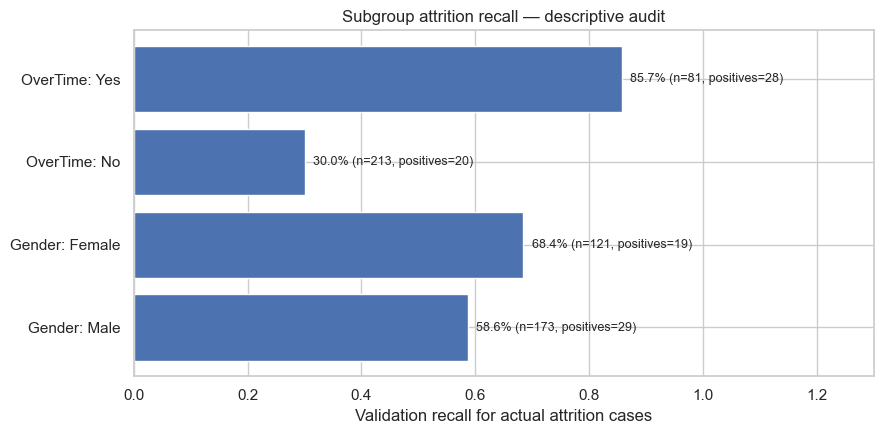

In [9]:
# Quantitative validation subgroup audit for the selected model and threshold.
subgroup_rows = []
yvp = (p_val >= chosen_threshold).astype(int)
actual_all = y_val.to_numpy()
MIN_GROUP_N = 30
MIN_POSITIVES = 10

for feature in ['Gender', 'OverTime']:
    if feature not in X_val.columns:
        print(f'Skipping {feature}: column unavailable')
        continue
    for group_value in X_val[feature].drop_duplicates().tolist():
        mask = (X_val[feature].isna() if pd.isna(group_value)
                else X_val[feature].eq(group_value)).to_numpy()
        actual = actual_all[mask]
        predicted = yvp[mask]
        if len(actual) == 0:
            continue
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        positive_count = int(tp + fn)
        negative_count = int(tn + fp)
        predicted_positive = int(tp + fp)
        subgroup_rows.append({
            'Dimension': 'Demographic' if feature == 'Gender' else 'Working condition',
            'Feature': feature,
            'Group': 'Missing' if pd.isna(group_value) else str(group_value),
            'N': len(actual),
            'Attrition cases': positive_count,
            'Attrition prevalence': positive_count / len(actual),
            'Accuracy': accuracy_score(actual, predicted),
            'Balanced accuracy': ((tp / positive_count + tn / negative_count) / 2
                                  if positive_count and negative_count else np.nan),
            'Precision': tp / predicted_positive if predicted_positive else np.nan,
            'Recall': tp / positive_count if positive_count else np.nan,
            'Specificity': tn / negative_count if negative_count else np.nan,
            'False positive rate': fp / negative_count if negative_count else np.nan,
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
            'Interpretation flag': ('Small group / few positives'
                                    if len(actual) < MIN_GROUP_N or positive_count < MIN_POSITIVES
                                    else 'Descriptive only')
        })

subgroup_df = pd.DataFrame(subgroup_rows).sort_values(['Feature', 'N'], ascending=[True, False]).reset_index(drop=True)
display(subgroup_df.round(3).style.format(na_rep='N/A'))
subgroup_df.to_csv(RESULTS / 'validation_subgroups.csv', index=False)
print('Saved results: validation_subgroups.csv')

# Plot subgroup recall and group size for context; N/A recall remains missing.
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = subgroup_df['Feature'] + ': ' + subgroup_df['Group']
ax.barh(labels, subgroup_df['Recall'].fillna(0))
for i, row in subgroup_df.iterrows():
    val = row['Recall']
    ax.text((val if pd.notna(val) else 0) + 0.015, i,
            f"{val:.1%} (n={row['N']}, positives={row['Attrition cases']})" if pd.notna(val)
            else f"N/A (n={row['N']}, positives=0)", va='center', fontsize=9)
ax.set_xlim(0, 1.30)
ax.set_xlabel('Validation recall for actual attrition cases')
ax.set_title('Subgroup attrition recall — descriptive audit')
plt.tight_layout()
save_plot('validation_subgroup_recall.png')
plt.show()

### Subgroup Audit Results — Interpretation

The subgroup audit evaluates the selected model at the validation-selected threshold of **0.60**, using **294 validation records**. These descriptive results do not establish whether the model is fair or discriminatory.

**Gender:** Recall was **58.6% for Male employees** (17 of 29 departures detected) and **68.4% for Female employees** (13 of 19 detected), a **9.8-percentage-point** difference. False-positive rates were **12.5%** and **9.8%**, respectively. Given the small numbers of attrition cases, these differences should be interpreted cautiously.

**Overtime:** Recall was **30.0% without overtime** (6 of 20 departures detected), compared with **85.7% with overtime** (24 of 28 detected). The overtime group also had a higher false-positive rate (**22.6% versus 8.3%**). The groups differ in attrition prevalence, and `OverTime` is a strong predictive feature; neither observation establishes causality.

**Ethical implications:** The model detects departures unevenly across subgroups, especially among employees without overtime. Before real-world use, performance should be reassessed on representative, time-stamped data, with uncertainty estimates, appropriate fairness checks, and safeguards against automated individual employment decisions.

## 20. Fairness, Privacy, and Measurement Risks

The quantitative audit in the subgroup audit sections examines **error distribution**, not causal discrimination or legal compliance. `Gender` is a demographic grouping; `OverTime` is a job-condition grouping. Differences in group prevalence, small positive counts, and synthetic construction can all affect observed metrics. The audit does not cover all relevant demographics, intersections, or employment contexts.

Because employment predictions could influence livelihoods, individual scores must **not** be used to deny promotion, discipline employees, or decide termination. Any proposed real-world study would require lawful data access, purpose limitation, minimization, employee consultation, subgroup uncertainty estimates, independent review, and prospective external validation. Keep subgroup exports aggregated and access-controlled.

## 21. Final Held-Out Test Evaluation
The selected training-CV configuration is refit on train+validation. The frozen validation threshold is applied once to test. Do not change the model, threshold, or features based on the test output and then call the same test untouched.

,0
Model,Logistic Regression | Class weights | Tuned
Threshold,0.6
Test AP,0.617859
Prevalence baseline AP,0.159864
ROC-AUC,0.804548
Accuracy,0.802721
Balanced accuracy,0.753381
Precision,0.426667
Recall,0.680851
Specificity,0.825911


              precision    recall  f1-score   support

           0       0.93      0.83      0.88       247
           1       0.43      0.68      0.52        47

    accuracy                           0.80       294
   macro avg       0.68      0.75      0.70       294
weighted avg       0.85      0.80      0.82       294

Saved figure: final_test_confusion_matrix.png


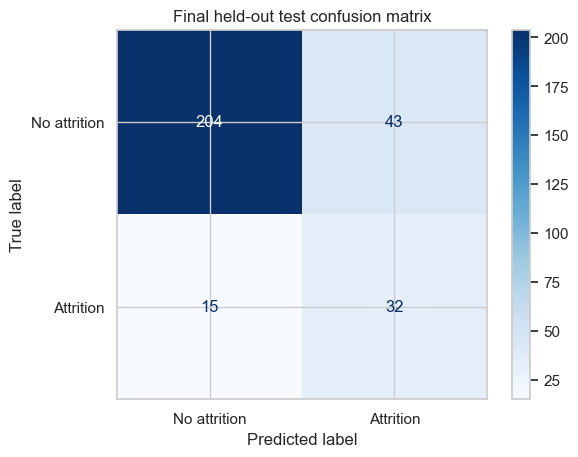

Saved model: final_model.joblib


In [10]:
X_dev=pd.concat([X_train,X_val]); y_dev=pd.concat([y_train,y_val])
final_model=make_pipe(winning_key[0],winning_key[1])
# Preserve selected tuned parameters when applicable.
# The estimator from the search contains all tuned values; copy only model's estimator params.
if winning_key[2]=='Tuned':
    final_model.named_steps['model'].set_params(**selected.named_steps['model'].get_params())
final_model.fit(X_dev,y_dev)
p_test=final_model.predict_proba(X_test)[:,1]
y_test_pred=(p_test>=chosen_threshold).astype(int)
tn,fp,fn,tp=confusion_matrix(y_test,y_test_pred,labels=[0,1]).ravel()
final_metrics=pd.DataFrame([{'Model':' | '.join(winning_key),'Threshold':chosen_threshold,
    'Test AP':average_precision_score(y_test,p_test),'Prevalence baseline AP':y_test.mean(),
    'ROC-AUC':roc_auc_score(y_test,p_test),'Accuracy':accuracy_score(y_test,y_test_pred),
    'Balanced accuracy':balanced_accuracy_score(y_test,y_test_pred),
    'Precision':precision_score(y_test,y_test_pred,zero_division=0),
    'Recall':recall_score(y_test,y_test_pred,zero_division=0),
    'Specificity':tn/(tn+fp) if tn+fp else np.nan,
    'TN':tn,'FP':fp,'FN':fn,'TP':tp}])
display(final_metrics.T);final_metrics.to_csv(RESULTS/'final_test_metrics.csv',index=False)
print(classification_report(y_test,y_test_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,display_labels=['No attrition','Attrition'],cmap='Blues')
plt.title('Final held-out test confusion matrix');save_plot('final_test_confusion_matrix.png');plt.show()
dump({'model':final_model,'threshold':chosen_threshold,'features':X.columns.tolist()},RESULTS/'final_model.joblib')
print('Saved model: final_model.joblib')

### Final Model Results — Interpretation

The held-out test has **294 observations** and **47 departures**. At threshold **0.60**, the refitted model produced **TP=32, FN=15, FP=43, TN=204**: **AP=0.6179** (prevalence baseline **0.1599**), **ROC-AUC=0.8045**, **accuracy=80.27%**, **balanced accuracy=75.34%**, **precision=42.67%**, **recall=68.09%**, and **specificity=82.59%**. Of 75 positive flags, **43 were false positives**.

### Cross-partition generalization check

| Measure | Training CV | Validation | Held-out test |
|---|---:|---:|---:|
| Average precision (AP) | **0.6503** (five-fold mean; SD **0.0635**) | **0.6202** | **0.6179** |
| ROC-AUC | Not recorded | **0.8457** | **0.8045** |
| Precision at 0.60 | Not recorded | **51.72%** | **42.67%** |
| Recall at 0.60 | Not recorded | **62.50%** | **68.09%** |

AP decreased **0.0301** from CV to validation and **0.0023** from validation to test; ROC-AUC fell **0.0412** from validation to test. Precision decreased **9.05 percentage points** while recall rose **5.59 points**. Small positive counts (**48 validation**, **47 test**) and refitting on **training plus validation** may contribute; these comparisons do not establish external validity or statistically significant superiority.

**Selection and threshold caveats.** CV scores were used for both tuning and ranking, so the best CV result may be optimistic. The **0.60** threshold was selected on validation predictions from the training-only fit, then transferred unchanged to the train+validation refit; probability scores may shift after refitting. No test-based threshold adjustment was made. Revising the model after viewing test results would require a new untouched test sample for unbiased final evaluation.

### Majority-Class Benchmark Comparison

On this test split, always predicting `No` would correctly classify **247 / 294 ≈ 84.0%** of records, yet achieve **0% attrition recall** and **50% balanced accuracy**. The selected model has **lower overall accuracy (80.27%)** but substantially better recall and balanced accuracy. This demonstrates why choosing the highest accuracy would be misleading for the research objective.

## 22. Research Question Answers

### RQ1. Which employee characteristics are most influential in predicting attrition, particularly overtime, job satisfaction, and work environment satisfaction?

Validation permutation importance for the selected model identified **`OverTime`** as the strongest predictor (mean AP decrease **0.2461**), followed by **`JobSatisfaction` (0.0666)**, **`EnvironmentSatisfaction` (0.0561)**, **`TotalWorkingYears` (0.0531)**, and **`JobInvolvement` (0.0427)**. These are measures of the model's reliance on recorded variables, **not causal estimates**. In particular, the analysis cannot show that reducing overtime would reduce departures. A retention team could investigate aggregate workload, satisfaction, and working conditions using appropriately governed, voluntary research rather than individual risk scores.

### RQ2. How effectively can machine learning predict employee attrition, and which model provides the strongest cross-validated performance?

The predefined five-fold training-CV ranking selected **tuned, class-weighted Logistic Regression** among **24 configurations** covering Logistic Regression, Decision Tree, Random Forest, and XGBoost. Its mean CV AP was **0.6503** (SD **0.0635**), with validation AP **0.6202**. The final held-out test achieved **AP 0.6179**, compared with the **test prevalence baseline of 0.1599**, and **ROC-AUC 0.8045**. However, tuned unweighted Logistic Regression had CV AP **0.6498** and a higher validation AP (**0.6583**); the weighted model's CV advantage of **0.0005** does not establish meaningful superiority. Results demonstrate ranking ability on synthetic records, not real-world readiness.

### RQ3. How do class imbalance strategies and hyperparameter tuning affect attrition prediction performance and incorrect prediction rates?

The experiment evaluated **original training, class weighting, and fold-safe SMOTE** for each of four algorithms, with baseline and randomized-tuned versions (**10 search candidates**, **five-fold CV**). For original-data Logistic Regression, tuning changed CV AP from **0.6443 to 0.6498** and validation AP from **0.6263 to 0.6583**. For class-weighted Logistic Regression, tuning changed CV AP from **0.6407 to 0.6503** and validation AP from **0.5731 to 0.6202**. These matched examples show improvements but **do not establish that tuning or weighting consistently improves all configurations**. The weighted winner had lower validation AP than the tuned unweighted alternative. Ordinary SMOTE after one-hot encoding can create unrealistic intermediate categorical values. Because incorrect positive flags matter, threshold-specific precision and false-positive counts must accompany AP; the methods alone do not guarantee fewer errors.

### RQ4. How do classification thresholds, prediction errors, and subgroup performance differences affect the reliability of employee attrition predictions?

The threshold **0.60** was selected on validation predictions to maximize F1 subject to recall of at least **50%**. On the final held-out test (**294 records; 47 departures**), the refitted model produced **TP=32, FN=15, FP=43, TN=204**, corresponding to **precision 42.67%**, **recall 68.09%**, **specificity 82.59%**, and **balanced accuracy 75.34%**. Thus, **43 of 75** positive flags were incorrect, and **15 of 47** actual departures were missed. On validation, lowering the threshold to **0.45** raised recall to **81.25%** but reduced precision to **39.39%**; this is a *validation* trade-off, not an alternate held-out test result.

The **validation subgroup audit** found recall of **58.6%** for male employees (17/29 departures) and **68.4%** for female employees (13/19); recall was **30.0%** without overtime (6/20) and **85.7%** with overtime (24/28). Small subgroup counts and synthetic data preclude conclusions about discrimination or real-world reliability. The threshold is not an approved HR decision rule.

### RQ5. Based on influential predictors, prediction errors, and subgroup differences, which workforce conditions should retention teams investigate, and what safeguards should they consider?

The model suggests **three exploratory investigation priorities**: (1) aggregate overtime and workload patterns, (2) employee-reported job satisfaction, and (3) work-environment concerns. These priorities follow from validation permutation importance, **not demonstrated causal effects**. A retention team could use voluntary surveys, aggregated workforce reviews, and employee consultation to determine whether these issues exist in its own organization; the synthetic dataset does not show which interventions work.

**Required safeguards** include avoiding individual employment decisions or employee surveillance based on model scores; obtaining appropriately governed, representative real-world data; validating prospectively and over time; protecting privacy; involving employees and HR stakeholders; examining subgroup sample sizes, false-positive rates, and recall with uncertainty estimates; and monitoring model drift. The **43 test false positives**, **15 false negatives**, and validation subgroup disparities show why predictive scores should remain an educational research finding rather than a deployed personnel tool (National Institute of Standards and Technology, 2023).

## 23. Assumptions

The dataset is treated as an educational synthetic snapshot; `Attrition` is correctly encoded as `Yes`/`No`; records are independently sampled for stratified splitting; predictor columns are treated as available for this synthetic benchmark, although actual prediction-time availability is unverified; and the fixed random seed supports reproducibility. These assumptions are not independently verified for real employment settings.

## 24. Limitations

**Synthetic data:** no demonstrated external validity. **Small positive sample:** only 47 positive test cases, so recall and precision are uncertain. **Cross-sectional design:** no causal inference or timing guarantees. **Class imbalance:** a high overall accuracy can conceal missed departures. **Limited subgroup audit:** gender and overtime slices do not establish fairness. **Single holdout:** performance may vary under a different split or workforce distribution.

## 25. Challenges

Key challenges include class imbalance, choosing a metric aligned with identifying departures, balancing false positives against false negatives, and preventing preprocessing or SMOTE leakage. The analysis mitigates some risks with fold-safe pipelines, stratified partitions, validation-only threshold selection, and a frozen test evaluation; external validity remains unresolved.

## 26. Future Uses

Possible research extensions include evaluation on properly consented, real, time-stamped organizational data; prospective monitoring for drift; repeated outer cross-validation or a truly independent external test; calibration assessment; and studying whether aggregate, voluntary workplace improvements change outcomes. None of these steps is performed in this notebook.

**Research progression (not a deployment plan):** First, reproduce the analysis and verify predictor timing. Next, obtain appropriate governance approval and independent, consented, time-stamped data. Then examine out-of-time performance, calibration, subgroup errors, and potential harms with affected stakeholders. Only after independent validation should any carefully restricted, aggregate decision-support use even be considered.

## 27. Recommendations and Potential Retention Research

Use this notebook as a **portfolio demonstration of reproducible classification**, not a production HR scoring system. The feature-importance analysis suggests that a retention team could **investigate aggregate workload/overtime, job satisfaction, and work-environment conditions** through voluntary surveys, employee consultation, and privacy-preserving organizational research. These are **hypotheses for investigation**, not proven causes of attrition or tested retention interventions.

When communicating predictive findings, report AP alongside the appropriate partition's prevalence baseline, thresholded recall and precision, confusion-matrix counts, and subgroup sample sizes. Given the **43 false positives and 15 false negatives on the held-out test**, do not use employee-level scores for hiring, discipline, monitoring, or retention decisions. Any future organizational study would need representative, appropriately consented data, time-based external validation, fairness and privacy assessments, and human governance (National Institute of Standards and Technology, 2023).

## 28. Ethical Assessment

### Identify: Risks and stakeholders

Attrition scores could affect employee privacy, reputation, trust, and employment opportunities. Stakeholders include employees, managers, HR teams, leaders, and employee representatives. Risks include **unfair treatment, intrusive data use, unequal errors, and treating predictions as facts**. The IBM dataset is **synthetic**; associations involving `OverTime`, satisfaction, pay, or demographic variables neither establish causes of departure nor justify individual actions.

### Assess: Errors and subgroup evidence

On the held-out test, the selected model identified **32 of 47 departures** (**68.09% recall**), missed **15**, and falsely flagged **43 stayers** (**42.67% precision**). False positives could lead to unwarranted scrutiny; false negatives limit detection. More than half of positive flags were incorrect in this sample, making automated employee-level intervention inappropriate.

The **validation** subgroup audit found recall **0.586 for Male (n=173)** versus **0.684 for Female (n=121)**, and specificity **0.875 versus 0.902**. These are small-sample descriptive differences, **not proof of fairness or discrimination**. `OverTime` is a work-condition grouping, not a demographic fairness category. Broader protected-group and intersectional audits would be needed for real-world use.

### Mitigate: Responsible safeguards

**In this notebook**, fold-safe preprocessing and resampling reduce leakage, while class-sensitive metrics, a held-out test, subgroup checks, and explicit limitations make errors visible. The notebook does **not** endorse individual employment decisions.

**Before considering organizational use:**

1. Validate with **consented, representative, time-stamped data**, checking temporal leakage and drift.
2. Restrict the purpose to **beneficial, preferably aggregate workforce analysis**; exclude disciplinary, promotion, pay, or termination decisions.
3. Apply **data minimization, access controls, retention limits, and clear employee disclosures**.
4. Evaluate **group and intersectional error rates**, documenting uncertainty and investigating disparities.
5. Require **human oversight, employee input, accountability, and opportunities to contest harmful outcomes**.
6. **Monitor performance and impact**, stopping use if validity or safeguards fail.

**Ethical conclusion.** This is an educational machine learning comparison, **not a validated employee-risk scoring system**. Its results support cautious methodological discussion, not automated decisions about people.

## 29. Code and Reproducibility

**Core libraries:** pandas, NumPy, matplotlib, seaborn, scikit-learn, imbalanced-learn, XGBoost, and joblib. **Input:** `data/WA_Fn-UseC_-HR-Employee-Attrition.csv`. **Outputs:** `figures/` for saved plots and `results/` for model comparison, validation threshold trade-offs, validation permutation importance, subgroup audit, final test metrics, and serialized final model. The seed is **42**. The notebook contains saved execution outputs. If the source data, dependencies, or model code change, rerun from the first cell and verify that all narrative results still match the new outputs.

## 30. Conclusion

This educational experiment compared four algorithms, three imbalance strategies, and baseline/tuned configurations on the synthetic IBM HR dataset. The selected **tuned, class-weighted Logistic Regression** achieved **test AP 0.6179** versus a **0.1599 test prevalence baseline**, identifying **32 of 47** recorded departures at threshold **0.60** while generating **43 false-positive flags**. Its slight CV advantage over the tuned unweighted model does not establish meaningful superiority.

In response to the business-focused research questions, validation permutation importance highlighted **OverTime**, **JobSatisfaction**, and **EnvironmentSatisfaction** as possible topics for aggregate workforce investigation. Prediction errors and descriptive subgroup recall differences argue against individual employee scoring. The results do **not** establish causal drivers, effective retention interventions, or deployment readiness. Further work requires appropriately governed real-world data, prospective validation, and employee-centered safeguards.

## 31. References

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953

IBM. (n.d.). *IBM HR analytics employee attrition & performance* [Data set]. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

National Institute of Standards and Technology. (2023). *Artificial intelligence risk management framework (AI RMF 1.0)* (NIST AI 100-1). https://doi.org/10.6028/NIST.AI.100-1

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432
